In [1]:
pip install yfinance

Note: you may need to restart the kernel to use updated packages.


In [2]:
import unicodedata
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set(color_codes=True)
sns.set(style="whitegrid")
import os
ticker_symbol = "^DJI"
data = yf.download(ticker_symbol, period="max")
data.to_csv('Dow Jones Industrial Average_data.csv')
print("Data downloaded and saved as Dow Jones Industrial Averagedata_data.csv")


[*********************100%***********************]  1 of 1 completed

Data downloaded and saved as Dow Jones Industrial Averagedata_data.csv


In [3]:
import warnings
warnings.filterwarnings('ignore')

In [4]:
ticker_symbol = "^DJI"
start_date="2026-10-12",
end_date="2026-10-14"
csv_path="Dow Jones Industrial Average_data"

In [5]:
data = yf.download("^DJI", start="2026-10-12", end="2026-10-14", auto_adjust=False)

if isinstance (data.columns, pd.MultiIndex):
    data.columns = data.columns.get_level_values(0)
    
data = data.dropna(subset=["Close", "Adj Close"])
data.to_csv("Dow Jones Industrial Average.csv")

print(data)

[*********************100%***********************]  1 of 1 completed

Price          Adj Close         Close          High           Low  \
Date                                                                 
2026-10-12  51850.550781  51850.550781  51928.101562  51718.601562   
2026-10-13  51670.101562  51670.101562  52317.320312  51587.671875   

Price               Open     Volume  
Date                                 
2026-10-12  51765.351562  307460000  
2026-10-13  52092.988281  395690000  


Lets have a look ate the data

In [6]:
df=pd.read_csv("Dow Jones Industrial Average.csv")

lets see available variables and the size of the data set

In [7]:
df.head()

,Date,Adj Close,Close,High,Low,Open,Volume
0,2026-10-12,51850.550781,51850.550781,51928.101562,51718.601562,51765.351562,307460000
1,2026-10-13,51670.101562,51670.101562,52317.320312,51587.671875,52092.988281,395690000


In [8]:
print(df.columns.tolist())

['Date', 'Adj Close', 'Close', 'High', 'Low', 'Open', 'Volume']


In [9]:
df.shape

(2, 7)

In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Date       2 non-null      str    
 1   Adj Close  2 non-null      float64
 2   Close      2 non-null      float64
 3   High       2 non-null      float64
 4   Low        2 non-null      float64
 5   Open       2 non-null      float64
 6   Volume     2 non-null      int64  
dtypes: float64(5), int64(1), str(1)
memory usage: 244.0 bytes


i'm gonna remove the first 2 rows beacuase they contain description and ticker information rather that actual stock-market data

In [11]:
df = df.drop([0, 1])

In [12]:
df.head()

,Date,Adj Close,Close,High,Low,Open,Volume


i rename the Price column to Date . Its easy to understand 

In [13]:
df = df.rename(columns={"Price": "Date"})

i convert the price and volume columns to numeric values so they can be used corrctly calculations and analysis

In [14]:
df[["Close", "High","Low","Open","Volume"]] = df[["Close", "High","Low","Open","Volume"]].astype(float)

In [15]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 0 entries
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Date       0 non-null      str    
 1   Adj Close  0 non-null      float64
 2   Close      0 non-null      float64
 3   High       0 non-null      float64
 4   Low        0 non-null      float64
 5   Open       0 non-null      float64
 6   Volume     0 non-null      float64
dtypes: float64(6), str(1)
memory usage: 132.0 bytes


In [16]:
df["Date"]= pd.to_datetime(df["Date"])

In [17]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 0 entries
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype        
---  ------     --------------  -----        
 0   Date       0 non-null      datetime64[s]
 1   Adj Close  0 non-null      float64      
 2   Close      0 non-null      float64      
 3   High       0 non-null      float64      
 4   Low        0 non-null      float64      
 5   Open       0 non-null      float64      
 6   Volume     0 non-null      float64      
dtypes: datetime64[s](1), float64(6)
memory usage: 132.0 bytes


In [18]:
df= df.set_index("Date")

In [19]:
df.head()

,Adj Close,Close,High,Low,Open,Volume
Date,,,,,,


In [20]:
df = df.rename(columns={"Price": "Date"})

In [21]:
df.head()

,Adj Close,Close,High,Low,Open,Volume
Date,,,,,,


In [22]:
df.isnull().sum()

Adj Close    0
Close        0
High         0
Low          0
Open         0
Volume       0
dtype: int64

In [23]:
df.describe()

,Adj Close,Close,High,Low,Open,Volume
count,0.0,0.0,0.0,0.0,0.0,0.0
mean,NaN,NaN,NaN,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN
max,NaN,NaN,NaN,NaN,NaN,NaN


Closing price Visualisation: i plot the DJIA closing prices over time to identify long_term trends and nocable market fluctuations

<Axes: title={'center': 'Dow Jones Closing Price'}, xlabel='Date'>

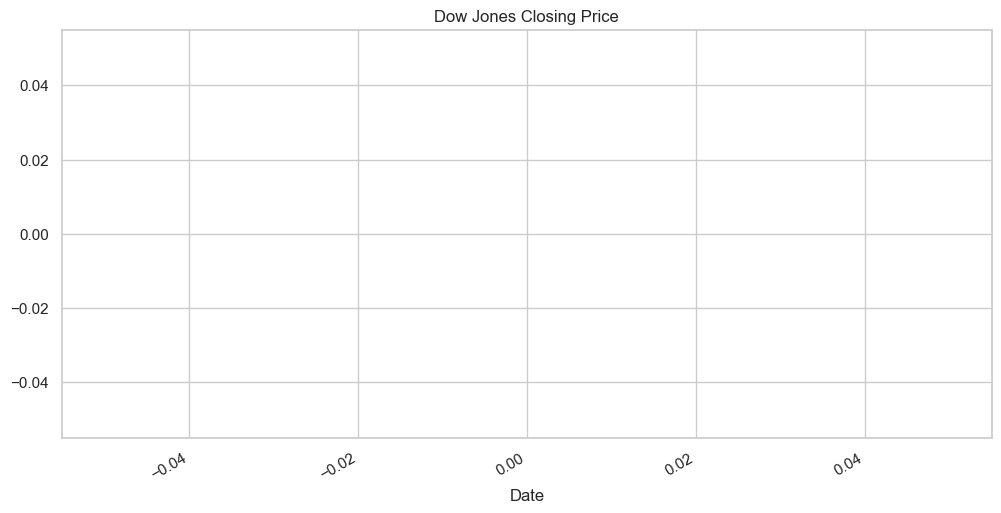

In [24]:
df["Close"].plot(figsize=(12, 6), title="Dow Jones Closing Price")

In [25]:
plt.show()

In [26]:
df["Daily_Return"] = df["Close"].pct_change() * 100
df[["Close", "Daily_Return"]].head()

,Close,Daily_Return
Date,,


Calculate the daily percentage of change 

In [27]:
df["Daily_Return"] = df["Close"].pct_change() * 100

In [28]:
df["Daily_Return"].isnull().sum()

np.int64(0)

In [29]:
df = df.dropna(subset=["Daily_Return"])

check missing values

In [30]:
df.isnull().sum()

Adj Close       0
Close           0
High            0
Low             0
Open            0
Volume          0
Daily_Return    0
dtype: int64

Calculate the avarege daily return 

In [31]:
df["Daily_Return"].mean()

nan

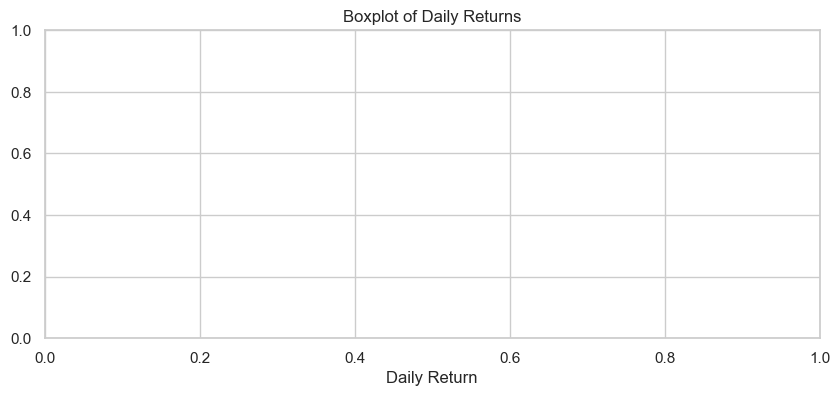

In [32]:
plt.figure(figsize=(10, 4))
sns.boxplot(x=df["Daily_Return"])
plt.title("Boxplot of Daily Returns")
plt.xlabel("Daily Return")

plt.show()

In [61]:
print(df["Daily_Return"].describe())

count    0.0
mean     NaN
std      NaN
min      NaN
25%      NaN
50%      NaN
75%      NaN
max      NaN
Name: Daily_Return, dtype: float64


Lets creat new column 

In [62]:
df["Daily_Range"] = df["High"] - df["Low"]

df["Open_Close_Change"] = (
    (df["Close"] - df["Open"]) / df["Open"]
) * 100

In [63]:
print(df.columns.tolist())

['Adj Close', 'Close', 'High', 'Low', 'Open', 'Volume', 'Daily_Return', 'Daily_Range', 'Open_Close_Change']


In [64]:
print(df[["Daily_Range", "Open_Close_Change"]].head())

Empty DataFrame
Columns: [Daily_Range, Open_Close_Change]
Index: []


Select the clustering features

In [65]:
features = [
    "Daily_Return",
    "Daily_Range",
    "Open_Close_Change",
    "Volume",
]

X = df[features].copy()

print(X.head())

Empty DataFrame
Columns: [Daily_Return, Daily_Range, Open_Close_Change, Volume]
Index: []


Open_CLose_Cahnge are both 0.917290. They happen to be equal for that day, but the two features measure different things and won't generally be equal.

In [66]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print (X_scaled[:5])

ValueError: Found array with 0 sample(s) (shape=(0, 4)) while a minimum of 1 is required by StandardScaler.

In [67]:
original_df = pd.read_csv("Dow Jones Industrial Average_data.csv")

print(original_df.columns.tolist())

['Price', 'Close', 'High', 'Low', 'Open', 'Volume']


In [68]:
print(original_df.head())

        Price             Close               High                Low  \
0      Ticker              ^DJI               ^DJI               ^DJI   
1        Date               NaN                NaN                NaN   
2  1992-01-02  3172.39990234375    3172.6298828125   3139.31005859375   
3  1992-01-03            3201.5  3210.639892578125     3165.919921875   
4  1992-01-06  3200.10009765625     3213.330078125  3191.860107421875   

               Open    Volume  
0              ^DJI      ^DJI  
1               NaN       NaN  
2  3152.10009765625  23550000  
3  3172.39990234375  23620000  
4            3201.5  27280000  


In [69]:
df["Daily_Return"] = df["Close"].pct_change() * 100

df["Daily_Range"] = df["High"] - df["Low"]

df["Open_Close_Change"] = (
    (df["Close"] - df["Open"]) / df["Open"]
) * 100

In [14]:
from sklearn.preprocessing import StandardScaler

features = [
    "Daily_Return",
    "Daily_Range",
    "Open_Close_Change",
    "Volume"
]

X = df[features].copy()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [33]:
print(df.shape)
print(df.columns.tolist())
print(df.head())

(0, 7)
['Adj Close', 'Close', 'High', 'Low', 'Open', 'Volume', 'Daily_Return']
Empty DataFrame
Columns: [Adj Close, Close, High, Low, Open, Volume, Daily_Return]
Index: []
